In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
print(np.__version__)


from astropy.io import fits

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.26.4


In [3]:
if 1:
    import importlib
    importlib.reload(util);


In [4]:
def LB2xyz(L, B, radians=False):
    """
        transform between Galactic coordinates and xyz-coordinates
    INPUT:
       L, B - angles in galactic coordinates in degrees or radians
    OUTPUT:
       x, y, z - unit vector in the direction of (L, B)
    """
    if not radians:
        L = np.deg2rad(L)
        B = np.deg2rad(B)
    x = np.cos(B) * np.cos(L)
    y = np.cos(B) * np.sin(L)
    z = np.sin(B)
    return np.array([x, y, z]).T

In [5]:
folder = '../../results/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/'
fn = folder + '4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_prob_cat.csv'
#summary_fn = fn.replace('prob_cat.csv', 'summary.csv')
cat_df = pd.read_csv(fn, index_col=0)

summary_fn = fn.replace('prob_cat.csv', 'summary.csv')
sum_df = pd.read_csv(summary_fn, index_col=0)



In [6]:
sum_df

,Class label,Node,Physical classes,N assoc,RF assoc,NN assoc,"RF unas,unk,bcu,spp","NN unas,unk,bcu,spp"
Group,,,,,,,,
1,fsrq+,0,"nlsy1, css, fsrq",833,838.6 +- 3.0,836.0 +- 1.9,1153.2 +- 4.5,1158.3 +- 3.4
2,bll+,10,"ssrq, rdg, sbg, sey, bll, agn",1564,1565.8 +- 3.0,1559.6 +- 2.1,1796.7 +- 4.4,1754.9 +- 2.9
3,psr+,100,"hmb, psr, lmb, nov",167,161.5 +- 1.7,165.4 +- 2.0,408.2 +- 3.5,512.0 +- 3.8
4,snr+,110,"bin, snr, gc, sfr, pwn",83,80.0 +- 1.3,83.1 +- 1.8,250.2 +- 2.5,231.2 +- 3.4
5,msp+,111,"glc, gal, msp",219,220.1 +- 1.9,221.9 +- 1.9,716.7 +- 4.1,668.5 +- 3.4


In [7]:
if 1:
    GeV2MeV = 1000.
    fn = '../../data_in/gll_psc_v32.fit'
    cat_hdu = fits.open(fn)
    ctab = cat_hdu[1].data 
    #Epivot = np.array(ctab['Pivot_Energy']) / GeV2MeV
    #Fpivot = np.array(ctab['LP_Flux_Density']) * GeV2MeV
    
    names = np.array([str(x).strip() for x in ctab['Source_Name']], dtype=str)
    cols = ['GLAT', 'GLON', 'Conf_95_SemiMajor']
    data_arr = []
    for col in cols:
        data = np.array(ctab[col])
        data_arr.append(data)
        
    df_extra = pd.DataFrame(index=names, columns=cols, data=np.array(data_arr).T)
    df_extra = df_extra.loc[cat_df.index]
    smajor95 = df_extra['Conf_95_SemiMajor']

In [8]:
nFGL = LB2xyz(df_extra['GLON'], df_extra['GLAT'])

In [9]:
tulip_fn = '../../data_in/LOFAR_TULIPP_radio/lofar_tulipp_radio_new.csv'
tulip_df = pd.read_csv(tulip_fn, index_col=None)
ntulip = LB2xyz(tulip_df['Lon'], tulip_df['Lat'])

In [10]:
ntulip.shape

(22, 3)

In [11]:
dist = np.zeros(len(ntulip))
unc = np.zeros(len(ntulip))
for i, n in enumerate(ntulip):
    sprod = np.dot(nFGL, n)
    thetas = np.rad2deg(np.arccos(sprod))
    ind = np.argmin(thetas)
    dist[i] = thetas[ind]
    unc[i] = smajor95[ind]
    #print('%.2f, %.2f' % (thetas[ind], ))

/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_7929/690821210.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  unc[i] = smajor95[ind]


In [12]:
# there seem to be no new PSR candidates among tulip sources close to 4FGL sources
np.sort(dist / unc)

array([  1.78580828,   1.96015836,   4.00702424,   6.69469563,
         9.24522116,   9.4972387 ,  10.69609702,  14.01329583,
        14.95175215,  15.72677792,  15.88233473,  18.09499365,
        18.99130197,  24.26038604,  24.65779681,  27.85567587,
        28.96471859,  31.37915486,  45.24476561,  46.57516385,
        77.3443652 , 120.175406  ])

In [13]:
# test MSC catalog
res_fn = '../../data_in/LOFAR_TULIPP_radio/MSC_assoc_vs_pcat.csv'
msc_fn = '../../data_in/LOFAR_TULIPP_radio/MSC_assoc.csv'
msc_df = pd.read_csv(msc_fn, index_col='4FGL name')
#len(msc_df)
msc_df

,MSC name,Spectral Index,LP SigCurv,Signif Avg,Candidate Type
4FGL name,,,,,
4FGL J0159.0+3313,MSC J015905.20+331257.6,-0.55,0.36,8.84,bll
4FGL J0409.2+2542,MSC J040921.74+254442.0,-0.86,1.21,7.39,bll
4FGL J0800.9+0733,MSC J080056.56+073235.0,-0.66,3.56,9.12,bll
4FGL J0838.5+4013,MSC J083855.81+401736.1,-0.84,0.43,4.13,bll
4FGL J0914.5+6845,MSC J091429.68+684508.4,-0.68,0.37,8.56,bll
4FGL J1557.2+3822,MSC J155734.66+382030.1,-0.51,1.50,4.00,bll
4FGL J0037.2-2653,MSC J003655.87-265215.2,-0.71,0.41,4.20,blz
4FGL J0137.3-3239,MSC J013724.50-324039.3,-0.16,1.16,5.18,blz
4FGL J0406.2+0639,MSC J040607.94+063922.0,-0.93,0.12,4.22,blz


In [14]:
cat_df_names = list(cat_df.index)
inside = [name in cat_df_names for name in msc_df.index]
msc_df = msc_df[inside]
msc_names = msc_df.index
len(msc_names)
#inside = np.array([name in cat_df_names for name in msc_names])
#inds = [cat_df_names.index(name) for name in msc_names if name in cat_df_names]


51

In [15]:
msc_names

Index(['4FGL J0159.0+3313', '4FGL J0409.2+2542', '4FGL J0800.9+0733',
       '4FGL J0838.5+4013', '4FGL J0914.5+6845', '4FGL J1557.2+3822',
       '4FGL J0037.2-2653', '4FGL J0137.3-3239', '4FGL J0406.2+0639',
       '4FGL J0723.1-3048', '4FGL J0737.4+6535', '4FGL J0755.9-0515',
       '4FGL J0906.1-1011', '4FGL J0934.5+7223', '4FGL J1047.2+6740',
       '4FGL J1049.8+2741', '4FGL J1111.4+0137', '4FGL J1114.6+1225',
       '4FGL J1122.0-0231', '4FGL J1224.6+7011', '4FGL J1256.8+5329',
       '4FGL J1648.7+4834', '4FGL J1818.5+2533', '4FGL J1856.1-1222',
       '4FGL J2326.9-4130', '4FGL J0204.7+6656', '4FGL J0533.6+5945',
       '4FGL J0752.0-2931', '4FGL J0752.0-2931', '4FGL J0754.9-3953',
       '4FGL J1203.5-1748', '4FGL J1203.5-1748', '4FGL J1356.6+0234',
       '4FGL J1407.7-3017', '4FGL J1407.7-3017', '4FGL J1530.0-1522',
       '4FGL J1711.0-3002', '4FGL J1735.3-0717', '4FGL J1739.3-2531',
       '4FGL J1747.0-3505', '4FGL J1805.7+3401', '4FGL J1813.5+2819',
       '4FGL J1908.7

In [16]:
pcat_msc = cat_df.loc[msc_names]

In [17]:
cols = ['FSRQ prob', 'BLL prob', 'PSR prob', 'MSP prob', 'PWN+SNR prob', 'MSC class', 'MSC name']
psr_df = pd.DataFrame(columns=cols, index=msc_names, dtype=float)

In [18]:
sum_df

,Class label,Node,Physical classes,N assoc,RF assoc,NN assoc,"RF unas,unk,bcu,spp","NN unas,unk,bcu,spp"
Group,,,,,,,,
1,fsrq+,0,"nlsy1, css, fsrq",833,838.6 +- 3.0,836.0 +- 1.9,1153.2 +- 4.5,1158.3 +- 3.4
2,bll+,10,"ssrq, rdg, sbg, sey, bll, agn",1564,1565.8 +- 3.0,1559.6 +- 2.1,1796.7 +- 4.4,1754.9 +- 2.9
3,psr+,100,"hmb, psr, lmb, nov",167,161.5 +- 1.7,165.4 +- 2.0,408.2 +- 3.5,512.0 +- 3.8
4,snr+,110,"bin, snr, gc, sfr, pwn",83,80.0 +- 1.3,83.1 +- 1.8,250.2 +- 2.5,231.2 +- 3.4
5,msp+,111,"glc, gal, msp",219,220.1 +- 1.9,221.9 +- 1.9,716.7 +- 4.1,668.5 +- 3.4


In [19]:
psr_df['PSR prob'].loc[msc_names] = pcat_msc['3_RF'][msc_names]

/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_7929/1793448545.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  psr_df['PSR prob'].loc[msc_names] = pcat_msc['3_RF'][msc_names]


In [20]:
#prec = 4
psr_df['PSR prob'].loc[msc_names] = pcat_msc['3_RF'][msc_names]
psr_df['MSP prob'].loc[msc_names] = pcat_msc['5_RF'][msc_names]
psr_df['FSRQ prob'].loc[msc_names] = pcat_msc['1_RF'][msc_names]
psr_df['BLL prob'].loc[msc_names] = pcat_msc['2_RF'][msc_names]
psr_df['PWN+SNR prob'].loc[msc_names] = pcat_msc['4_RF'][msc_names]
psr_df['MSC class'].loc[msc_names] = msc_df['Candidate Type'][msc_names]
psr_df['MSC name'].loc[msc_names] = msc_df['MSC name'][msc_names]
#psr_df = np.round(psr_df, decimals=prec)

/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_7929/145948421.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  psr_df['PSR prob'].loc[msc_names] = pcat_msc['3_RF'][msc_names]
/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ip

In [26]:
nshow = 3
inds = list(range(nshow)) + list(range(len(psr_df) - nshow, len(psr_df)))
psr_df.iloc[inds]

,FSRQ prob,BLL prob,PSR prob,MSP prob,PWN+SNR prob,MSC class,MSC name
4FGL name,,,,,,,
4FGL J0159.0+3313,0.029865,0.969724,0.000002,0.000330,0.000079,bll,MSC J015905.20+331257.6
4FGL J0409.2+2542,0.072426,0.889651,0.000015,0.024070,0.013838,bll,MSC J040921.74+254442.0
4FGL J0800.9+0733,0.137263,0.709764,0.021278,0.127862,0.003833,bll,MSC J080056.56+073235.0
4FGL J2117.0+1344,0.038279,0.122460,0.024286,0.814910,0.000065,psr,MSC J211654.13+134155.8
4FGL J2117.0+1344,0.038279,0.122460,0.024286,0.814910,0.000065,psr,MSC J211709.60+134416.4
4FGL J2250.5+3305,0.026383,0.011489,0.129387,0.829312,0.003429,psr,MSC J225020.87+330429.7


In [27]:
len(psr_df.index)

51

In [28]:
comment = 'Comparison of candidates in arxiv:2212.05115 with probabilistic classification in arxiv:2401.04565'
psr_df.to_csv(res_fn, float_format='%.4f', index_label='4FGL name')

In [29]:
psr_df.to_csv?

Signature:
psr_df.to_csv(
    path_or_buf: 'FilePath | WriteBuffer[bytes] | WriteBuffer[str] | None' = None,
    *,
    sep: 'str' = ',',
    na_rep: 'str' = '',
    float_format: 'str | Callable | None' = None,
    columns: 'Sequence[Hashable] | None' = None,
    header: 'bool_t | list[str]' = True,
    index: 'bool_t' = True,
    index_label: 'IndexLabel | None' = None,
    mode: 'str' = 'w',
    encoding: 'str | None' = None,
    compression: 'CompressionOptions' = 'infer',
    quoting: 'int | None' = None,
    quotechar: 'str' = '"',
    lineterminator: 'str | None' = None,
    chunksize: 'int | None' = None,
    date_format: 'str | None' = None,
    doublequote: 'bool_t' = True,
    escapechar: 'str | None' = None,
    decimal: 'str' = '.',
    errors: 'OpenFileErrors' = 'strict',
    storage_options: 'StorageOptions | None' = None,
) -> 'str | None'
Docstring:
Write object to a comma-separated values (csv) file.

Parameters
----------
path_or_buf : str, path object, file-like obj

In [30]:
prob_dict = {}
agn_mask = (psr_df['MSC class'] == 'bll') | (psr_df['MSC class'] == 'blz')
prob_dict['agn'] = psr_df['BLL prob'][agn_mask] + psr_df['FSRQ prob'][agn_mask]
psr_mask = psr_df['MSC class'] == 'psr'
prob_dict['psr'] = (psr_df['PSR prob'] + psr_df['MSP prob'])[psr_mask]


Text(0, 0.5, 'Number of sources')

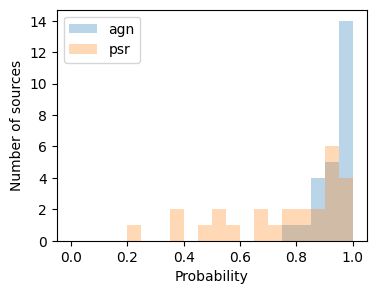

In [36]:
pyplot.figure(figsize=[4,3])
bins = np.linspace(0, 1, 21)
for key, values in prob_dict.items():
    pyplot.hist(prob_dict[key], bins=bins, alpha=0.3, label=key)
pyplot.legend()
pyplot.xlabel('Probability')
pyplot.ylabel('Number of sources')

In [53]:
np.sort(np.array(prob_dict['psr']))

array([0.2332229 , 0.38629485, 0.38629485, 0.47787234, 0.50212766,
       0.50212766, 0.56313278, 0.66664438, 0.67583156, 0.73068102,
       0.75679331, 0.79383443, 0.83919553, 0.83919553, 0.85360182,
       0.87085106, 0.90041033, 0.90041033, 0.91212766, 0.94806008,
       0.94847011, 0.94847011, 0.9556383 , 0.95869837, 0.95871125,
       0.97191489])

In [38]:
np.sort(np.array(prob_dict['agn']))

array([0.75727801, 0.84702663, 0.85549643, 0.8727062 , 0.88596423,
       0.88871483, 0.92881211, 0.93622207, 0.93638614, 0.94382033,
       0.94494529, 0.95227008, 0.95851794, 0.95958941, 0.96207686,
       0.96333341, 0.97404255, 0.97405176, 0.98408022, 0.98826921,
       0.99330989, 0.99775998, 0.99812686, 0.99958929, 0.99963984])

In [35]:
pyplot.figure?

Signature:
pyplot.figure(
    num: 'int | str | Figure | SubFigure | None' = None,
    figsize: 'tuple[float, float] | None' = None,
    dpi: 'float | None' = None,
    *,
    facecolor: 'ColorType | None' = None,
    edgecolor: 'ColorType | None' = None,
    frameon: 'bool' = True,
    FigureClass: 'type[Figure]' = <class 'matplotlib.figure.Figure'>,
    clear: 'bool' = False,
    **kwargs,
) -> 'Figure'
Docstring:
Create a new figure, or activate an existing figure.

Parameters
----------
num : int or str or `.Figure` or `.SubFigure`, optional
    A unique identifier for the figure.

    If a figure with that identifier already exists, this figure is made
    active and returned. An integer refers to the ``Figure.number``
    attribute, a string refers to the figure label.

    If there is no figure with the identifier or *num* is not given, a new
    figure is created, made active and returned.  If *num* is an int, it
    will be used for the ``Figure.number`` attribute, otherwise, 